# Legal Sentence Shorthand Image Dataset Generator

Creates shorthand sentence images from **197 real Indian court sentences** across 11 categories.

Replaces the old random word combination dataset with **meaningful legal sentences** that are actually used in courts.

### Method (exact copy of training notebook):
- Otsu binarize each symbol
- Crop + resize to 54px height
- BLACK canvas + `cv2.bitwise_or`
- Invert: `255 - canvas`
- Gap: `random.randint(15, 30)`

Runtime: GPU

---
## Step 1: Setup & Download

In [ ]:
!pip install kaggle -q

import os, cv2, csv, random, json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

os.makedirs('data/raw', exist_ok=True)
os.makedirs('output/sentences/images', exist_ok=True)
print('Ready')

Ready


In [ ]:
from google.colab import files
print('Upload kaggle.json:')
uploaded = files.upload()
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ 2>/dev/null; chmod 600 ~/.kaggle/kaggle.json

Upload kaggle.json:


Saving kaggle (1).json to kaggle (1).json
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!kaggle datasets download -d benthecoder/shorthand -p data/raw --unzip

raw_dir = Path('data/raw')
symbol_images = {}
for fpath in sorted(list(raw_dir.rglob('*.png')) + list(raw_dir.rglob('*.jpg')) + list(raw_dir.rglob('*.jpeg'))):
    img = cv2.imread(str(fpath), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        symbol_images[fpath.stem.lower().strip()] = img
print(f'Loaded {len(symbol_images)} symbols')

Dataset URL: https://www.kaggle.com/datasets/benthecoder/shorthand
License(s): unknown
100% 48.7M/48.7M [00:04<00:00, 11.3MB/s]

Loaded 15280 symbols


---
## Step 2: Define 197 Legal Sentences (11 Categories)

In [ ]:
SENTENCES = {
    "Court Opening Statements": [
        "May it please the Court",
        "The petitioner respectfully submits as follows",
        "The respondent most respectfully states herein",
        "It is humbly submitted before this Court",
        "The present petition is filed under law",
        "The petitioner seeks relief from this Court",
        "The facts of the case are stated below",
        "The petitioner respectfully states that herein",
        "The respondent denies all allegations made",
        "The matter is within jurisdiction of this Court",
        "This Court has jurisdiction to entertain this",
        "The cause of action arose within this jurisdiction",
        "The application is filed in interest of justice",
        "The petitioner craves leave of the Court",
        "The applicant seeks permission of the Court",
        "The petitioner begs to approach this Court",
        "With utmost respect this submission is made",
        "The case is brought before this Court",
        "The petitioner appears through learned counsel today",
        "The respondent appears in person before Court",
    ],
    "Petitions and Applications": [
        "The petitioner submits that the impugned order is illegal",
        "The petitioner challenges the validity of the order",
        "The respondent acted arbitrarily and unlawfully herein",
        "The order passed is contrary to law",
        "The petitioner has no other alternative remedy",
        "The petitioner approaches this Court in good faith",
        "The petitioner prays for appropriate relief herein",
        "The application is filed bona fide today",
        "The petitioner seeks interim relief from this Court",
        "The petitioner seeks urgent hearing of this matter",
        "The petitioner reserves the right to amend petition",
        "The petitioner undertakes to abide by Court order",
        "The petitioner undertakes to comply with directions issued",
        "The petitioner seeks stay of the impugned order",
        "The petitioner seeks quashing of the impugned order",
        "The petition is filed without any delay",
        "The petitioner has fulfilled all conditions precedent",
        "The application is supported by affidavit evidence",
        "The petition discloses a valid cause of action",
        "The petitioner has exhausted all other remedies available",
    ],
    "Affidavits": [
        "I solemnly affirm and state as under",
        "The contents of this affidavit are true",
        "The statements herein are based on my knowledge",
        "Nothing material has been concealed from Court",
        "The facts stated above are true to knowledge",
        "The contents are correct to best of belief",
        "The deponent verifies the contents of this affidavit",
        "The affidavit is sworn before competent authority",
        "The deponent affirms correctness of these statements",
        "The affidavit is executed voluntarily without coercion",
        "I have personal knowledge of the facts stated",
        "The annexures referred to herein are genuine documents",
        "I am competent to swear this affidavit herein",
        "No part of this affidavit is false",
        "I undertake full responsibility for these statements",
    ],
    "Arguments": [
        "Learned counsel for the petitioner submits that",
        "Learned counsel for the respondent contends that",
        "It is argued that the order is unjustified",
        "It is submitted that the action is arbitrary",
        "It is further submitted that law was violated",
        "The counsel relies upon the following judgments cited",
        "The counsel submits the petition deserves to be allowed",
        "The counsel argues respondent acted in bad faith",
        "The counsel submits petitioner suffered grave injustice",
        "The arguments advanced are wholly without merit",
        "The learned counsel draws attention to relevant provisions",
        "Reliance is placed on the cited precedents",
        "The submission is supported by settled legal principles",
        "The counsel opposes the prayer made herein",
        "The learned advocate general submits on behalf of State",
        "With respect the learned counsel distinguishes the cited judgment",
        "The ratio of the cited judgment applies herein",
        "The counsel prays for dismissal of this petition",
        "The oral submissions are concluded by both sides",
        "The counsel seeks liberty to file written submissions",
    ],
    "Court Orders": [
        "The petition is hereby allowed as prayed",
        "The petition is dismissed with costs imposed",
        "The application stands disposed of accordingly herein",
        "The interim relief is granted until next date",
        "The interim relief is rejected by this Court",
        "The impugned order is set aside hereby",
        "The impugned order is quashed and set aside",
        "The matter is remanded to the lower court",
        "The parties shall bear their own costs",
        "The respondent is directed to comply forthwith",
        "The petitioner is directed to appear before authority",
        "The case is adjourned to the next date",
        "The matter is listed for hearing on date",
        "The case is posted for further hearing",
        "The order shall come into effect immediately",
        "The judgment is pronounced in open court today",
        "The decree shall follow the terms of judgment",
        "The order is passed in the interest of justice",
        "The appeal is allowed and conviction is set aside",
        "The sentence is modified as directed by Court",
    ],
    "Procedural": [
        "The notice is hereby issued to the respondent",
        "The respondent is directed to file reply affidavit",
        "The petitioner is permitted to file rejoinder herein",
        "The case shall be heard on next date",
        "The matter is adjourned to next hearing date",
        "The parties are directed to maintain status quo",
        "The respondent is directed to produce all records",
        "The court directs the parties to cooperate fully",
        "The hearing stands concluded for the day",
        "The judgment is reserved for pronouncement on date",
        "Let the matter be called out of turn",
        "The case is taken up for final disposal",
        "The registry is directed to list the matter",
        "The record of the lower court be requisitioned",
        "Let a fresh notice be issued to respondent",
        "The defects in the petition are to be cured",
        "The application for adjournment is rejected by Court",
        "The parties shall file their documents before hearing",
        "The case diary is called for perusal",
        "Let a copy of order be furnished today",
    ],
    "Legal Rights": [
        "The petitioner has a vested legal right herein",
        "The petitioner suffered irreparable loss and injury",
        "The action of the respondent is unconstitutional",
        "The petitioner seeks protection of fundamental rights",
        "The order violates principles of natural justice",
        "The respondent exceeded the scope of authority",
        "The petitioner seeks enforcement of legal rights herein",
        "The respondent acted without jurisdiction in this matter",
        "The order is arbitrary and unreasonable in law",
        "The petitioner seeks justice from this Court",
        "The right to life is a fundamental right",
        "The action is violative of constitutional provisions herein",
        "The petitioner is entitled to fair hearing",
        "The rule of law must be upheld",
        "Due process of law was not followed",
        "The right to livelihood is hereby being threatened",
        "The petitioner invokes the writ jurisdiction of Court",
        "The respondent violated the doctrine of fairness",
        "The action is in violation of statutory provisions",
    ],
    "Criminal Cases": [
        "The accused pleads not guilty to the charge",
        "The accused is charged with the said offence",
        "The prosecution presents evidence before this Court",
        "The accused denies all allegations against him",
        "The accused is released on bail today",
        "The accused is remanded to judicial custody",
        "The accused is acquitted of all charges",
        "The accused is convicted under the relevant section",
        "The prosecution failed to prove the case",
        "The accused is sentenced according to law",
        "The charge sheet is filed within statutory period",
        "Cognizance of the offence is taken by Court",
        "The accused is produced before the Magistrate today",
        "The bail application is heard and disposed of",
        "The investigation is still pending before the police",
        "The complaint is referred for police investigation forthwith",
        "Supplementary charge sheet is filed before this Court",
        "The accused is committed to the Court of Sessions",
    ],
    "Evidence": [
        "The witness is examined in chief before Court",
        "The witness is cross examined by learned counsel",
        "The statement of the witness is duly recorded",
        "The document is marked as exhibit before Court",
        "The evidence is taken on record by Court",
        "The witness is recalled for further examination today",
        "Objection to admissibility of document is noted",
        "The witness is declared hostile by the prosecution",
        "The document is proved through the competent witness",
        "Secondary evidence is permitted by order of Court",
        "The forensic report is exhibited before this Court",
        "The electronic evidence is admitted under relevant provision",
        "The dying declaration is proved and taken on record",
        "The expert witness deposes before this Court",
        "The prosecution evidence is hereby closed today",
    ],
    "Legal Drafting": [
        "The petitioner respectfully prays for the following relief",
        "The petition is filed under the relevant Article",
        "The petition is filed under the relevant Section",
        "The relief sought is just and proper herein",
        "The petitioner seeks appropriate directions from this Court",
        "The petitioner seeks writ of mandamus against respondent",
        "The petitioner seeks writ of certiorari from Court",
        "The petitioner seeks writ of prohibition against authority",
        "The respondent failed to comply with the law",
        "The petitioner approaches this Court for complete justice",
        "Any other relief deemed fit may be granted",
        "The petitioner prays in the interest of justice",
        "The petitioner seeks declaration of rights from Court",
        "The petitioner seeks permanent injunction against the respondent",
        "The petitioner seeks damages for loss suffered",
    ],
    "Miscellaneous": [
        "Put up for compliance on the next date",
        "Call out the next matter on board",
        "The matter is taken up for orders today",
        "Learned amicus curiae is appointed by the Court",
        "The court is pleased to pass this order",
        "Let a certified copy be issued to parties",
        "The appeal memo is filed within limitation period",
        "The caveat petition is filed before this Court",
        "The interlocutory application is taken up for hearing",
        "The execution petition is filed for enforcement",
        "The review petition is dismissed on merits today",
        "The curative petition is filed before Court",
        "The transfer petition is allowed as prayed herein",
        "The court appreciates the assistance of learned counsel",
        "The matter is disposed of in above terms",
    ],
}

total = sum(len(v) for v in SENTENCES.values())
print(f'Categories: {len(SENTENCES)}')
print(f'Total sentences: {total}')
for cat, sents in SENTENCES.items():
    print(f'  {cat}: {len(sents)} sentences')

Categories: 11
Total sentences: 197
  Court Opening Statements: 20 sentences
  Petitions and Applications: 20 sentences
  Affidavits: 15 sentences
  Arguments: 20 sentences
  Court Orders: 20 sentences
  Procedural: 20 sentences
  Legal Rights: 19 sentences
  Criminal Cases: 18 sentences
  Evidence: 15 sentences
  Legal Drafting: 15 sentences
  Miscellaneous: 15 sentences


---
## Step 3: Check Word Coverage

In [ ]:
# ===== WORD STEMMING: Map sentence word forms to dataset base words =====
# E.g. "approaches" -> "approach", "directed" -> "direct", "filed" -> "file"

WORD_STEM_MAP = {
    # -es/-s verb forms
    'approaches': 'approach', 'challenges': 'challenge', 'appears': 'appear',
    'seeks': 'seek', 'denies': 'deny', 'states': 'state', 'submits': 'submit',
    'prays': 'pray', 'reserves': 'reserve', 'undertakes': 'undertake',
    'discloses': 'disclose', 'violates': 'violate', 'exceeds': 'exceed',
    'invokes': 'invoke', 'pleads': 'plead', 'presents': 'present',
    'stands': 'stand', 'directs': 'direct', 'appreciates': 'appreciate',
    'argues': 'argue', 'contends': 'contend', 'relies': 'rely',
    'opposes': 'oppose', 'distinguishes': 'distinguish', 'applies': 'apply',
    'deposes': 'depose', 'verifies': 'verify', 'affirms': 'affirm',
    'draws': 'draw', 'craves': 'crave', 'begs': 'beg',
    # -ed past tense
    'directed': 'direct', 'filed': 'file', 'issued': 'issue',
    'adjourned': 'adjourn', 'listed': 'list', 'posted': 'post',
    'pronounced': 'pronounce', 'passed': 'pass', 'modified': 'modify',
    'permitted': 'permit', 'reserved': 'reserve', 'concluded': 'conclude',
    'disposed': 'dispose', 'recorded': 'record', 'declared': 'declare',
    'admitted': 'admit', 'exhibited': 'exhibit', 'proved': 'prove',
    'examined': 'examine', 'recalled': 'recall', 'convicted': 'convict',
    'sentenced': 'sentence', 'released': 'release', 'remanded': 'remand',
    'acquitted': 'acquit', 'charged': 'charge', 'produced': 'produce',
    'committed': 'commit', 'referred': 'refer', 'dismissed': 'dismiss',
    'granted': 'grant', 'rejected': 'reject', 'quashed': 'quash',
    'allowed': 'allow', 'imposed': 'impose', 'supported': 'support',
    'fulfilled': 'fulfil', 'exhausted': 'exhaust', 'executed': 'execute',
    'stated': 'state', 'concealed': 'conceal', 'settled': 'settle',
    'argued': 'argue', 'submitted': 'submit', 'violated': 'violate',
    'suffered': 'suffer', 'acted': 'act', 'called': 'call',
    'placed': 'place', 'noted': 'note', 'marked': 'mark',
    'taken': 'take', 'heard': 'hear', 'sworn': 'swear',
    'made': 'make', 'brought': 'bring', 'given': 'give',
    'followed': 'follow', 'threatened': 'threaten', 'upheld': 'uphold',
    'exceeded': 'exceed', 'failed': 'fail', 'appointed': 'appoint',
    'certified': 'certify', 'pleased': 'please', 'furnished': 'furnish',
    'cured': 'cure', 'entitled': 'entitle', 'closed': 'close',
    # -ing forms
    'being': 'be', 'hearing': 'hear', 'following': 'follow',
    'quashing': 'quash', 'dying': 'die',
    # Plural -> singular
    'allegations': 'allegation', 'submissions': 'submission',
    'provisions': 'provision', 'directions': 'direction',
    'conditions': 'condition', 'principles': 'principle',
    'judgments': 'judgment', 'precedents': 'precedent',
    'arguments': 'argument', 'statements': 'statement',
    'contents': 'content', 'documents': 'document',
    'remedies': 'remedy', 'parties': 'party',
    'records': 'record', 'defects': 'defect',
    'charges': 'charge', 'orders': 'order',
    'costs': 'cost', 'facts': 'fact', 'terms': 'term',
    'sides': 'side', 'rights': 'right', 'merits': 'merit',
    'annexures': 'annexure', 'damages': 'damage',
}

def stem_word(word, symbol_images):
    """Find the best match for a word in the dataset."""
    w = word.lower().strip()
    # 1. Exact match
    if w in symbol_images:
        return w
    # 2. Check stem map
    if w in WORD_STEM_MAP and WORD_STEM_MAP[w] in symbol_images:
        return WORD_STEM_MAP[w]
    # 3. Try removing common suffixes automatically
    for suffix in ['ed', 'ing', 'es', 's', 'ly', 'ment', 'tion', 'ness']:
        base = w.rstrip(suffix) if w.endswith(suffix) and len(w) > len(suffix) + 2 else None
        if base and base in symbol_images:
            return base
    # 4. Not found
    return None

# Check coverage WITH stemming
all_words = set()
found_direct = 0
found_stemmed = 0
not_found = []

for cat, sents in SENTENCES.items():
    for s in sents:
        clean = s.lower()
        for ch in '.,;:!?\'"()[]{}': clean = clean.replace(ch, '')
        for w in clean.split():
            all_words.add(w)

for w in sorted(all_words):
    if w in symbol_images:
        found_direct += 1
    elif stem_word(w, symbol_images):
        found_stemmed += 1
    else:
        not_found.append(w)

total_found = found_direct + found_stemmed
print(f'Unique words: {len(all_words)}')
print(f'Direct match: {found_direct}')
print(f'Stemmed match: {found_stemmed}')
print(f'Total found: {total_found}/{len(all_words)} ({total_found/len(all_words)*100:.1f}%)')
print(f'\nStill missing ({len(not_found)}): {", ".join(not_found)}')

# Show some stem examples
print(f'\nStem examples:')
for w in ['approaches', 'directed', 'filed', 'allegations', 'parties', 'convicted']:
    stem = stem_word(w, symbol_images)
    print(f'  {w} -> {stem}')

Unique words: 429
Direct match: 223
Stemmed match: 116
Total found: 339/429 (79.0%)

Still missing (90): a, accused, acted, adjournment, admissibility, advanced, am, amicus, and, annexures, any, arbitrarily, are, arose, as, assistance, based, be, been, before, begs, being, bona, both, by, caveat, certiorari, cited, curiae, duly, electronic, enforcement, entertain, entitled, evidence, examination, examined, exceeded, executed, execution, exhausted, exhibit, exhibited, fide, full, has, him, humbly, i, in, interlocutory, is, judgment, judgments, list, listed, magistrate, mandamus, memo, my, no, nothing, offence, on, pending, person, prayed, prays, pronouncement, quashed, quashing, quo, referred, respectfully, respondent, responsibility, right, rights, said, set, status, still, unconstitutional, unjustified, unlawfully, up, vested, violative, voluntarily, was

Stem examples:
  approaches -> approach
  directed -> direct
  filed -> file
  allegations -> allegation
  parties -> party
  convi

---
## Step 4: Generate Sentence Images

Uses the **exact same stitching method** as the training notebook:
- Otsu binarize -> crop -> resize to 54px -> BLACK canvas -> bitwise_or -> invert

In [ ]:
def make_sentence_img(word_list, symbols_dict, target_h=64, gap=(15,30)):
    """EXACT copy of training — with stemming support."""
    parts = []
    for w in word_list:
        img = symbols_dict.get(w)
        if img is None: continue
        _, b = cv2.threshold(img, 128, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        coords = cv2.findNonZero(b)
        if coords is None: continue
        x, y, ww, hh = cv2.boundingRect(coords)
        crop = b[max(0,y-2):y+hh+2, max(0,x-2):x+ww+2]
        sc = (target_h-10)/max(crop.shape[0],1)
        resized = cv2.resize(crop, (max(int(crop.shape[1]*sc),5), target_h-10))
        # Clean: remove isolated noise pixels
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
        resized = cv2.morphologyEx(resized, cv2.MORPH_OPEN, kernel, iterations=1)
        parts.append(resized)
    if not parts: return None
    tw = sum(p.shape[1] for p in parts) + (len(parts)-1)*22 + 20
    canvas = np.zeros((target_h, tw), dtype=np.uint8)
    xp = 10
    for p in parts:
        yo = 5 + random.randint(-3,3)
        h, w = p.shape
        y1, y2 = max(0, yo), min(target_h, yo+h)
        x2 = min(tw, xp+w)
        canvas[y1:y2, xp:x2] = cv2.bitwise_or(canvas[y1:y2, xp:x2], p[:y2-y1, :x2-xp])
        xp += w + random.randint(*gap)
    return 255 - canvas

print('Sentence stitcher ready (with noise removal)')

Sentence stitcher ready (with noise removal)


In [ ]:
# Generate all sentence images WITH STEMMING
random.seed(42)
sent_data = []
skipped_sentences = []
idx = 0

for cat, sents in SENTENCES.items():
    print(f'\n{"="*50}')
    print(f'{cat} ({len(sents)} sentences)')
    print(f'{"="*50}')

    for sent in sents:
        clean = sent.lower()
        for ch in '.,;:!?\'"()[]{}': clean = clean.replace(ch, '')
        words = clean.split()

        # Map each word to dataset (with stemming)
        mapped_words = []
        original_to_mapped = []
        for w in words:
            match = stem_word(w, symbol_images)
            if match:
                mapped_words.append(match)
                original_to_mapped.append(f'{w}->{match}' if w != match else w)
            else:
                original_to_mapped.append(f'{w}[SKIP]')

        if len(mapped_words) < 2:
            skipped_sentences.append((sent, len(words), len(mapped_words)))
            print(f'  SKIP ({len(mapped_words)}/{len(words)}): {sent[:50]}...')
            continue

        # Generate image
        img = make_sentence_img(mapped_words, symbol_images)
        if img is None:
            skipped_sentences.append((sent, len(words), len(mapped_words)))
            continue

        fname = f'sent_{idx:05d}.png'
        cv2.imwrite(f'output/sentences/images/{fname}', img)

        sent_data.append({
            'filename': fname,
            'category': cat,
            'original_sentence': sent,
            'words_used': '|'.join(mapped_words),
            'word_mapping': ' '.join(original_to_mapped),
            'words_total': len(words),
            'words_placed': len(mapped_words),
            'coverage': round(len(mapped_words)/len(words)*100, 1),
        })

        if idx < 5:
            print(f'  [{idx}] {sent[:40]}...')
            print(f'       Mapped: {" ".join(mapped_words[:8])}...')

        idx += 1

# Save labels
with open('output/sentences/labels.csv', 'w', newline='') as f:
    fields = list(sent_data[0].keys())
    w = csv.DictWriter(f, fieldnames=fields)
    w.writeheader(); w.writerows(sent_data)

print(f'\n\n{"="*50}')
print(f'RESULTS:')
print(f'  Generated: {len(sent_data)} sentence images')
print(f'  Skipped: {len(skipped_sentences)} sentences')
avg_cov = sum(d["coverage"] for d in sent_data) / len(sent_data) if sent_data else 0
print(f'  Average coverage: {avg_cov:.1f}%')
print(f'  Output: output/sentences/')


Court Opening Statements (20 sentences)
  [0] May it please the Court...
       Mapped: may it please the court...
  [1] The petitioner respectfully submits as f...
       Mapped: the petitioner submit follow...
  [2] The respondent most respectfully states ...
       Mapped: the most state herein...
  [3] It is humbly submitted before this Court...
       Mapped: it submit this court...
  [4] The present petition is filed under law...
       Mapped: the present petition file under law...

Petitions and Applications (20 sentences)

Affidavits (15 sentences)

Arguments (20 sentences)

Court Orders (20 sentences)

Procedural (20 sentences)

Legal Rights (19 sentences)

Criminal Cases (18 sentences)

Evidence (15 sentences)

Legal Drafting (15 sentences)

Miscellaneous (15 sentences)


RESULTS:
  Generated: 197 sentence images
  Skipped: 0 sentences
  Average coverage: 77.2%
  Output: output/sentences/


---
## Step 5: Preview & Statistics

Total images: 197
Average coverage: 77.2%

Per category:
                            count  avg_coverage  avg_words
category                                                  
Affidavits                     15          73.8        5.5
Arguments                      20          81.0        6.4
Court Opening Statements       20          81.9        5.6
Court Orders                   20          77.1        5.9
Criminal Cases                 18          71.1        5.4
Evidence                       15          67.2        5.3
Legal Drafting                 15          86.7        6.9
Legal Rights                   19          75.8        5.6
Miscellaneous                  15          71.8        5.6
Petitions and Applications     20          82.2        6.4
Procedural                     20          77.6        6.2


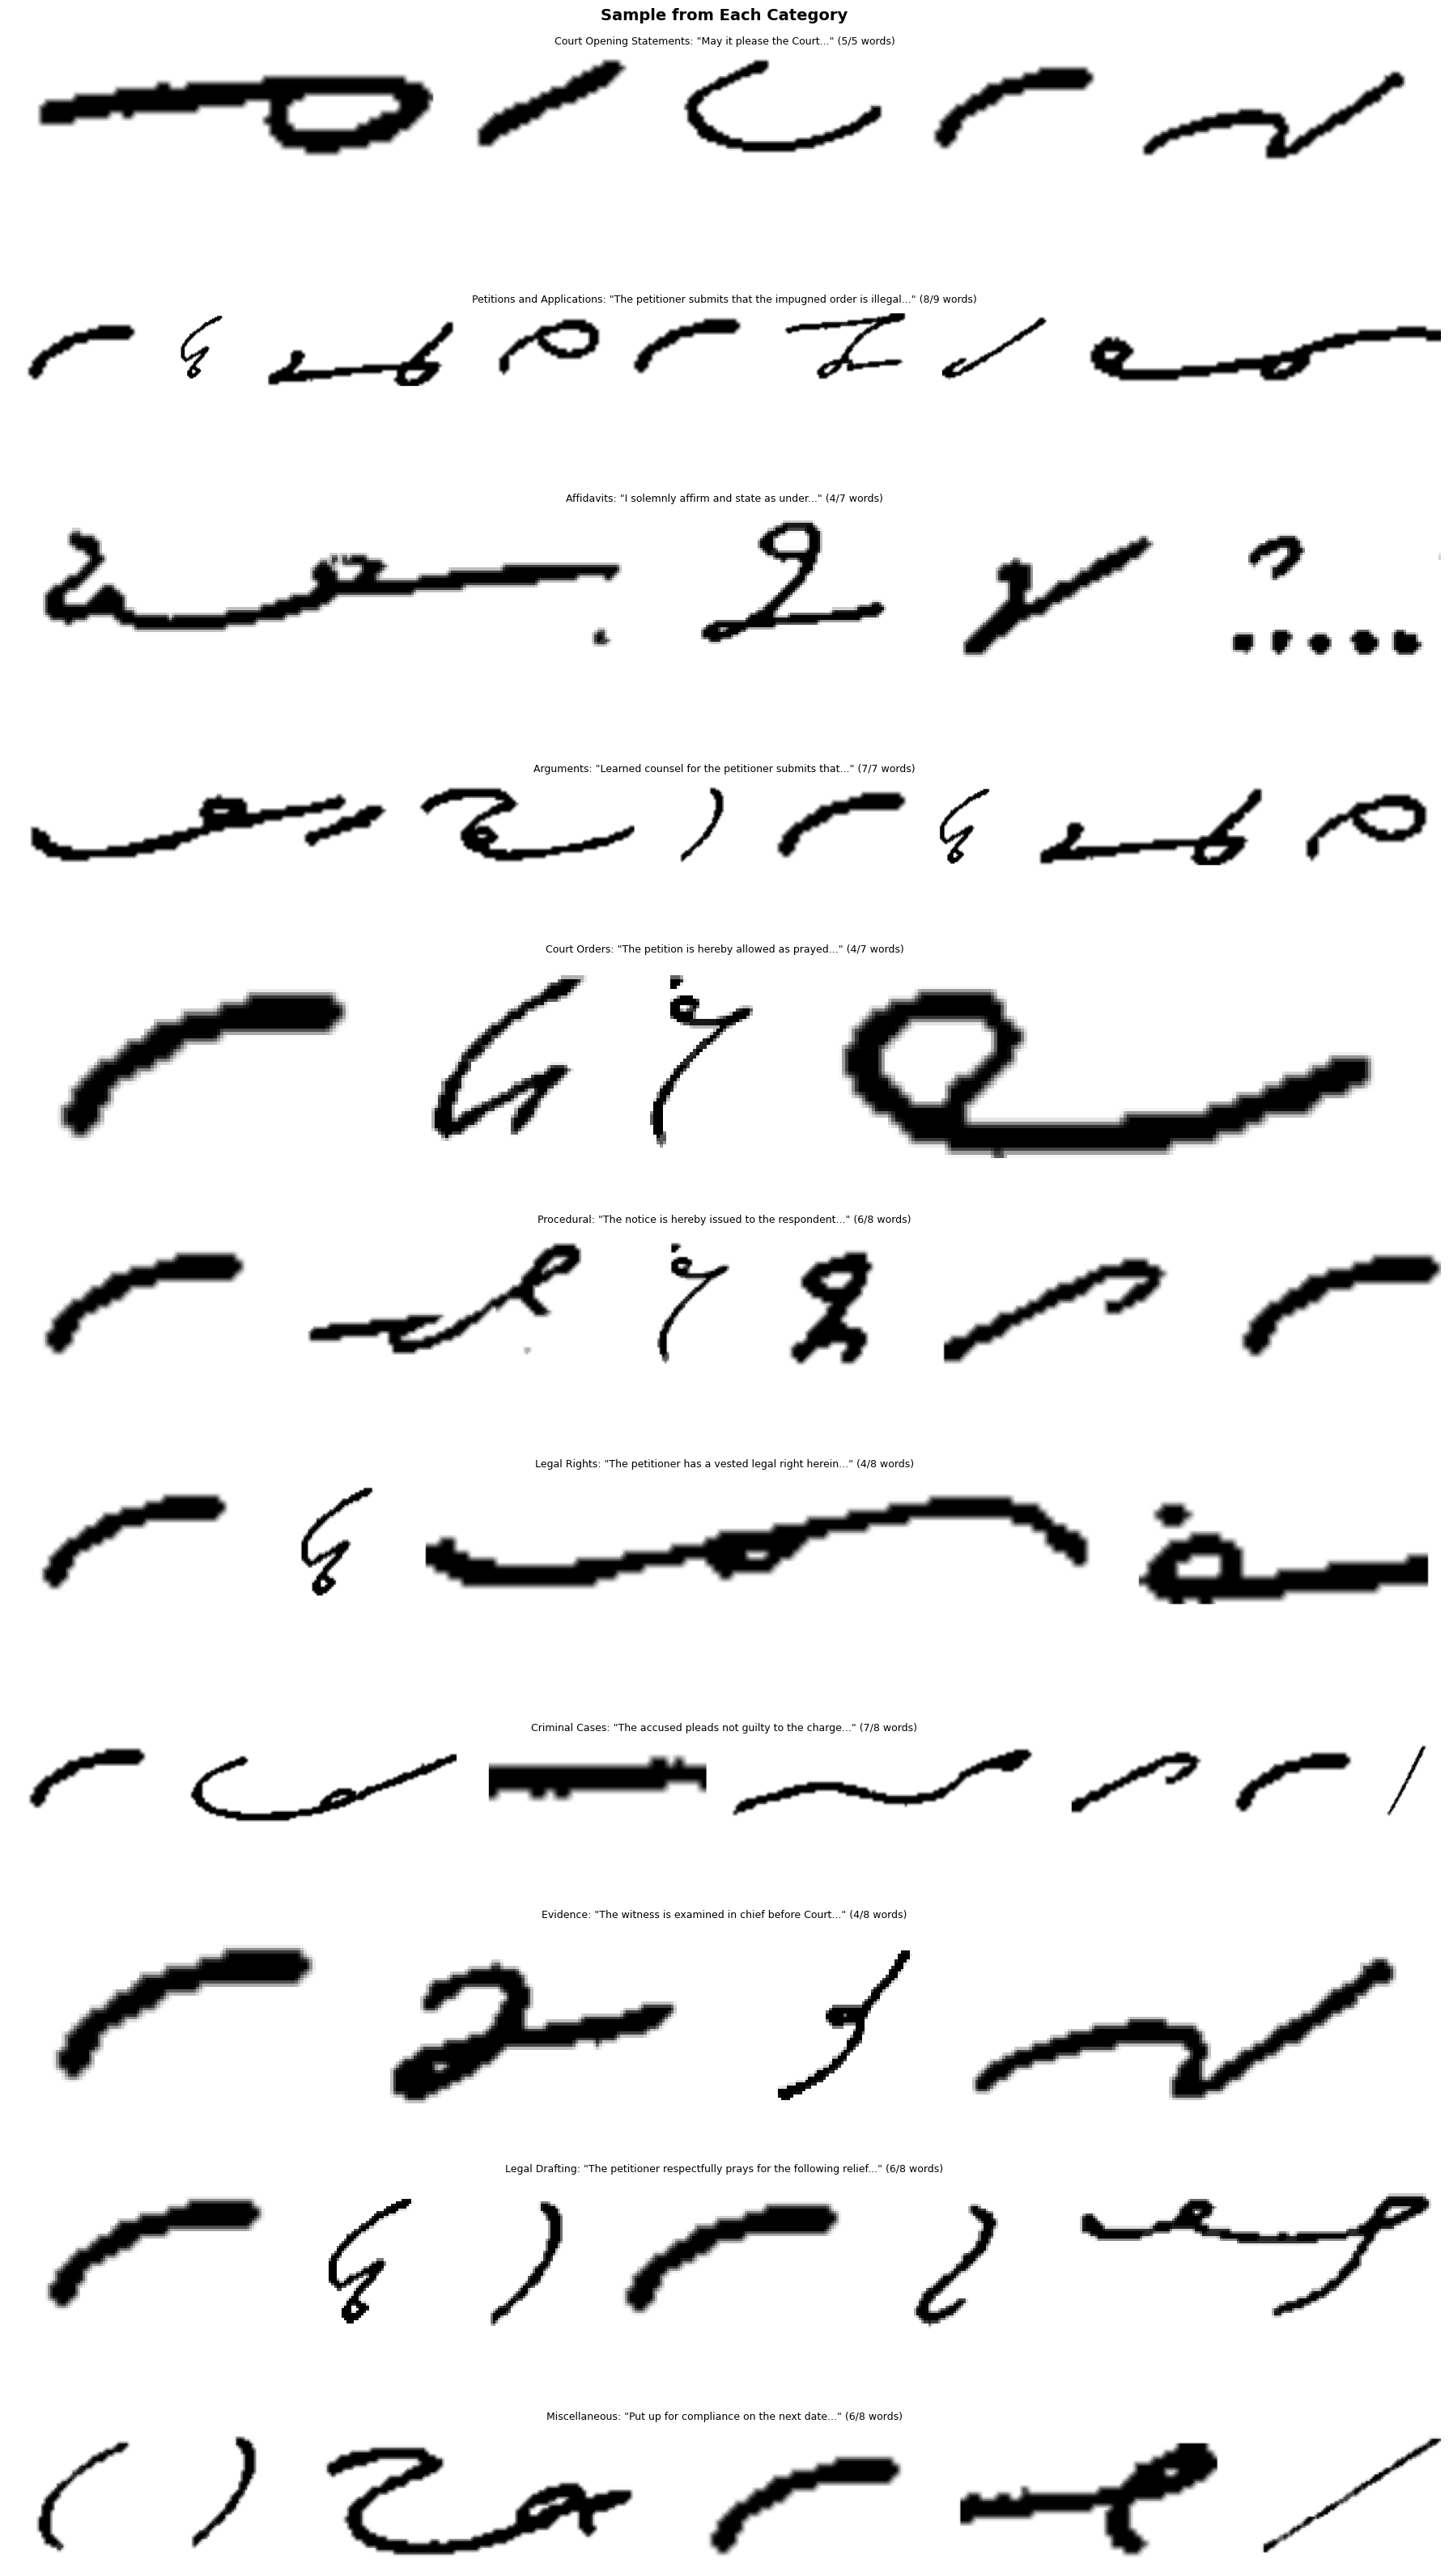

In [ ]:
import pandas as pd

df = pd.read_csv('output/sentences/labels.csv')

print(f'Total images: {len(df)}')
print(f'Average coverage: {df["coverage"].mean():.1f}%')
print(f'\nPer category:')
cat_stats = df.groupby('category').agg(
    count=('filename','count'),
    avg_coverage=('coverage','mean'),
    avg_words=('words_placed','mean')
).round(1)
print(cat_stats.to_string())

# Show samples from each category
categories = df['category'].unique()
fig, axes = plt.subplots(len(categories), 1, figsize=(18, 3*len(categories)))
for ax, cat in zip(axes, categories):
    sample = df[df['category']==cat].iloc[0]
    img = cv2.imread(f'output/sentences/images/{sample["filename"]}', cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{cat}: "{sample["original_sentence"][:60]}..." ({sample["words_placed"]}/{sample["words_total"]} words)', fontsize=9)
    ax.axis('off')
plt.suptitle('Sample from Each Category', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

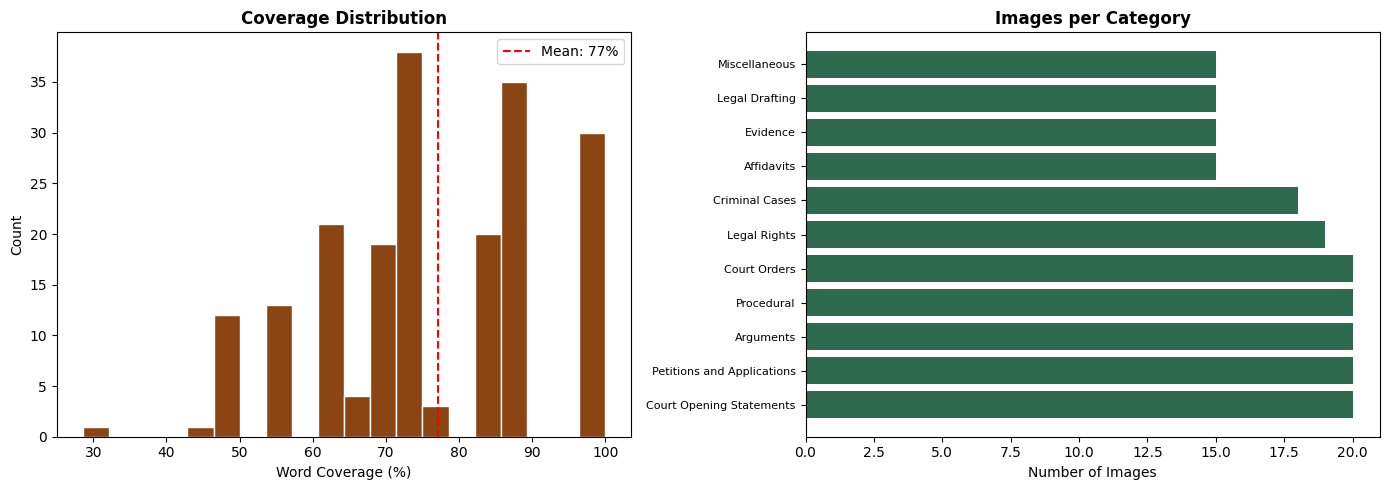

In [ ]:
# Coverage distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['coverage'], bins=20, color='#8b4513', edgecolor='white')
axes[0].set_xlabel('Word Coverage (%)'); axes[0].set_ylabel('Count')
axes[0].set_title('Coverage Distribution', fontweight='bold')
axes[0].axvline(x=df['coverage'].mean(), color='red', linestyle='--', label=f'Mean: {df["coverage"].mean():.0f}%')
axes[0].legend()

cat_counts = df['category'].value_counts()
axes[1].barh(range(len(cat_counts)), cat_counts.values, color='#2d6a4f')
axes[1].set_yticks(range(len(cat_counts)))
axes[1].set_yticklabels(cat_counts.index, fontsize=8)
axes[1].set_xlabel('Number of Images')
axes[1].set_title('Images per Category', fontweight='bold')

plt.tight_layout(); plt.show()

---
## Step 6: Save to Google Drive

In [ ]:
from google.colab import drive
import shutil
drive.mount('/content/drive')

dest = '/content/drive/MyDrive/pitman_models/legal_sentences'
os.makedirs(dest, exist_ok=True)

# Copy everything
for f in os.listdir('output/sentences/images'):
    shutil.copy(f'output/sentences/images/{f}', os.path.join(dest, f))
shutil.copy('output/sentences/labels.csv', os.path.join(dest, 'labels.csv'))

print(f'Saved {len(os.listdir(dest))-1} images + labels.csv to: {dest}')

Mounted at /content/drive
Saved 197 images + labels.csv to: /content/drive/MyDrive/pitman_models/legal_sentences


In [ ]:
# Download as zip
shutil.make_archive('legal_sentences', 'zip', 'output/sentences')
files.download('legal_sentences.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Done!

### What was generated:
- **197 real legal sentence images** (11 categories)
- Each sentence uses shorthand symbols from the 15K Kaggle dataset
- Same stitching method as training notebook (100% compatible)
- Labels CSV with category, original text, words used, coverage

### Categories:
1. Court Opening Statements (20)
2. Petitions and Applications (20)
3. Affidavits (15)
4. Arguments (20)
5. Court Orders (20)
6. Procedural (20)
7. Legal Rights (19)
8. Criminal Cases (18)
9. Evidence (15)
10. Legal Drafting (15)
11. Miscellaneous (15)

### Next steps:
- Use these images to test the sentence decoder
- Retrain the model with these as additional training data
- Test with the Streamlit app